# DBSCAN — klastry i szum


**Cel:** Rozpoznać grupy o nieregularnym kształcie i zrozumieć wpływ eps oraz min_samples.



## 1. Środowisko
Jeżeli brakuje bibliotek, odkomentuj poniższą instrukcję instalacji. Instalacja wymaga internetu, sama analiza już nie. Następnie uruchom ponownie kernel.

In [1]:
# %pip install numpy pandas matplotlib scikit-learn
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
SEED = 42
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.8.0


## Jak działa algorytm?
`eps` to promień sąsiedztwa, a `min_samples` to minimalna liczba punktów w tym sąsiedztwie, **łącznie z samym punktem**. Punkt rdzeniowy ma wystarczająco wielu sąsiadów. Punkt brzegowy leży w sąsiedztwie rdzenia, ale sam nie spełnia warunku rdzenia. Pozostałe punkty otrzymują etykietę **-1 (szum)**.

Nie podajemy liczby klastrów. Wynik zależy jednak od skali, metryki, eps i min_samples. Szum oznacza nietypowość względem tych ustawień, nie dowód błędu lub oszustwa.

## 2. Dane: dwa półksiężyce i dodatkowe losowe punkty

Liczba punktów: 535


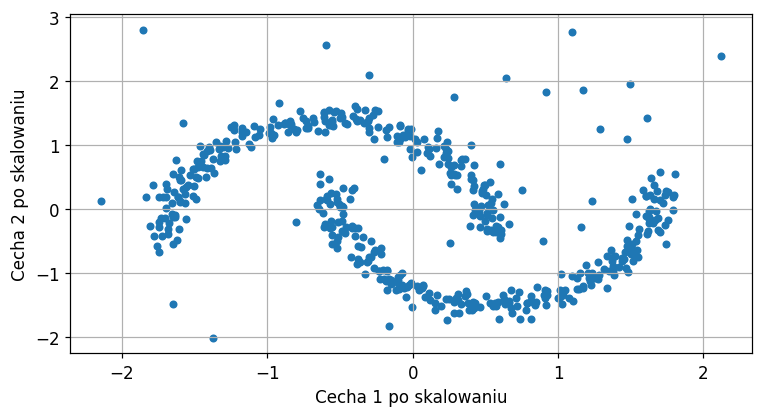

In [2]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
A, _ = make_moons(n_samples=500, noise=0.06, random_state=SEED)
rng = np.random.default_rng(SEED)
extra = rng.uniform(low=[-1.5,-0.8], high=[2.5,1.8], size=(35,2))
X = np.vstack([A, extra])
Z = StandardScaler().fit_transform(X)
plt.scatter(Z[:,0], Z[:,1], s=18)
plt.xlabel('Cecha 1 po skalowaniu'); plt.ylabel('Cecha 2 po skalowaniu'); plt.show()
print('Liczba punktów:', len(Z))

## 3. Wykres k-distance
Sortujemy odległość do `min_samples`-tego sąsiada, licząc punkt jako własnego sąsiada. Wzrost krzywej sugeruje zakres eps, ale nie wyznacza jednego obiektywnie poprawnego progu.

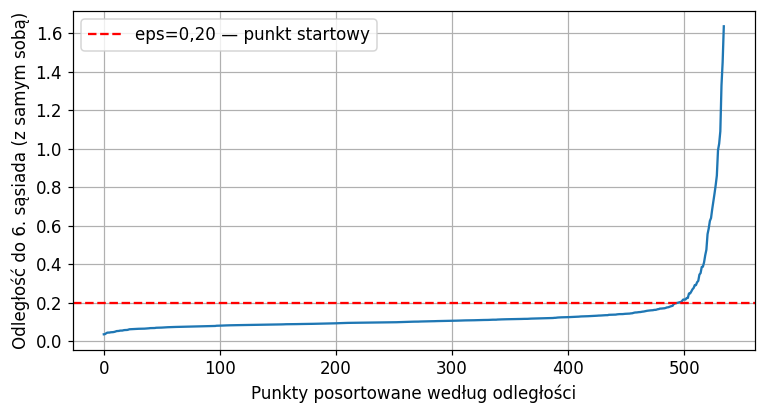

In [3]:
min_samples = 6
nn = NearestNeighbors(n_neighbors=min_samples).fit(Z)
distances, _ = nn.kneighbors(Z)
plt.plot(np.sort(distances[:, -1]))
plt.xlabel('Punkty posortowane według odległości'); plt.ylabel('Odległość do 6. sąsiada (z samym sobą)')
plt.axhline(0.20, color='red', linestyle='--', label='eps=0,20 — punkt startowy')
plt.legend(); plt.show()

## 4. Dopasowanie i rozróżnienie rdzenia, brzegu oraz szumu

Klastry: 2 | Szum: 24 | Rdzeń: 495 | Brzeg: 16


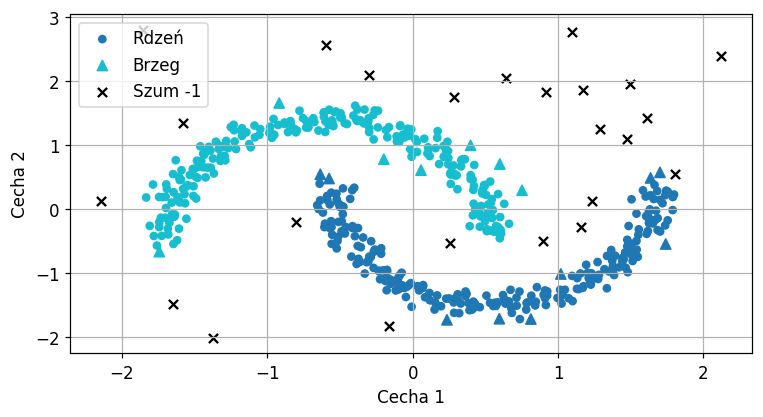

In [4]:
model = DBSCAN(eps=0.20, min_samples=min_samples).fit(Z)
labels = model.labels_
core = np.zeros(len(Z), dtype=bool)
core[model.core_sample_indices_] = True
noise = labels == -1
border = (~core) & (~noise)
n_clusters = len(set(labels) - {-1})
print('Klastry:', n_clusters, '| Szum:', noise.sum(), '| Rdzeń:', core.sum(), '| Brzeg:', border.sum())
for mask, marker, size, name in [(core, 'o', 22, 'Rdzeń'), (border, '^', 45, 'Brzeg')]:
    plt.scatter(Z[mask,0], Z[mask,1], c=labels[mask], cmap='tab10', vmin=0,
                vmax=max(1,n_clusters-1), marker=marker, s=size, label=name)
plt.scatter(Z[noise,0], Z[noise,1], c='black', marker='x', label='Szum -1')
plt.xlabel('Cecha 1'); plt.ylabel('Cecha 2'); plt.legend(); plt.show()

## 5. Wrażliwość na parametry
Silhouette liczymy tylko dla punktów niebędących szumem i tylko wtedy, gdy istnieją co najmniej dwa klastry oraz mniej klastrów niż punktów. Zawsze raportujemy także udział szumu: wysoki silhouette po odrzuceniu większości danych może mylić. Wydłużone klastry mogą mieć niższy silhouette mimo sensownego kształtu.

In [5]:
rows = []
for eps in [0.10, 0.15, 0.20, 0.30, 0.45]:
    for ms in [4, 6, 12]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        keep = lab != -1
        k = len(set(lab[keep]))
        sil = silhouette_score(Z[keep], lab[keep]) if 2 <= k < keep.sum() else np.nan
        rows.append({'eps': eps, 'min_samples': ms, 'klastry': k,
                     'szum_proc': 100*(~keep).mean(), 'silhouette_bez_szumu': sil})
display(pd.DataFrame(rows).round(3))

,eps,min_samples,klastry,szum_proc,silhouette_bez_szumu
0,0.10,4,11,14.206,0.290
1,0.10,6,24,21.495,0.431
2,0.10,12,1,97.009,NaN
3,0.15,4,2,7.103,0.398
4,0.15,6,2,7.477,0.398
5,0.15,12,13,18.318,0.494
6,0.20,4,2,4.299,0.386
7,0.20,6,2,4.486,0.387
8,0.20,12,2,6.355,0.396
9,0.30,4,2,3.738,0.381


## 6. Porównanie z K-means na tych samych danych

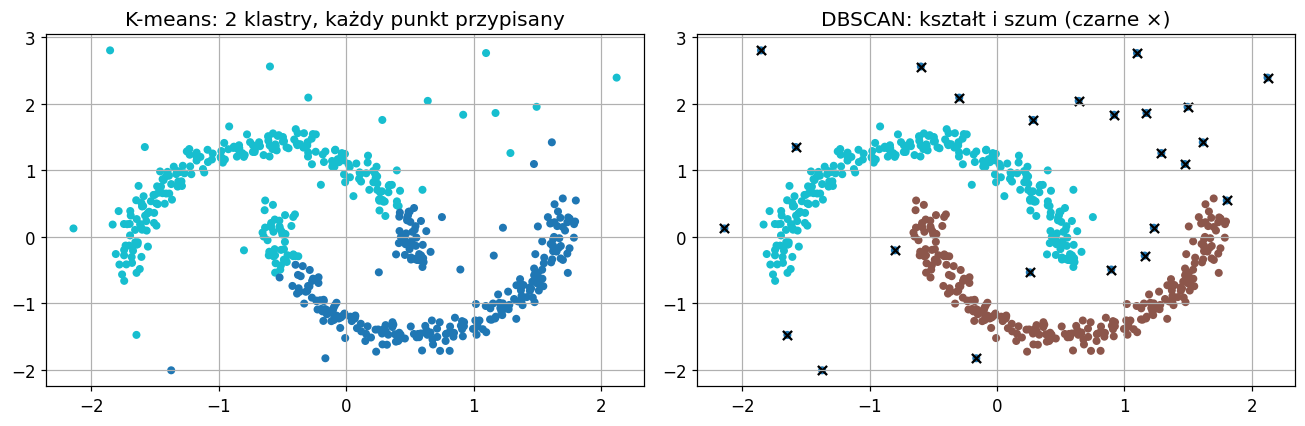

In [6]:
km = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit_predict(Z)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(Z[:,0], Z[:,1], c=km, cmap='tab10', s=18)
axes[0].set_title('K-means: 2 klastry, każdy punkt przypisany')
axes[1].scatter(Z[:,0], Z[:,1], c=labels, cmap='tab10', s=18)
axes[1].scatter(Z[noise,0], Z[noise,1], c='black', marker='x')
axes[1].set_title('DBSCAN: kształt i szum (czarne ×)')
plt.tight_layout(); plt.show()

K-means dzieli przestrzeń według odległości od centroidów; DBSCAN łączy obszary gęste. Nie istnieje uniwersalny zwycięzca. Przy zmiennej gęstości jedno eps może rozbić rzadką grupę i połączyć gęste grupy.

**Nowe dane:** implementacja DBSCAN w scikit-learn nie ma metody `predict`. Ponowne `fit` może zmienić poprzedni podział. Przypisywanie do pobliskiego rdzenia wymaga osobno zaprojektowanej reguły i nie jest standardowym przewidywaniem DBSCAN.

## 7. Ćwiczenia
1. Ustaw eps=0,05 i eps=0,8. Sprawdź liczbę klastrów i udział szumu.
2. Zwiększ `min_samples` przy stałym eps. Co dzieje się z liczbą punktów rdzeniowych?
3. Zwiększ `noise` generatora do 0,15. Czy wcześniejsze ustawienia nadal działają?
4. Wyjaśnij, dlaczego 35 dodanych losowych punktów nie musi dać 35 etykiet -1.
5. Podaj przykład biznesowy, w którym punkt nietypowy jest wartościowy.

**Wskazówki:** małe eps sprzyja szumowi i fragmentacji; duże może scalać grupy. Zwiększenie min_samples przy stałych danych i eps nie zwiększa liczby punktów rdzeniowych, ale liczba klastrów nie musi zmieniać się monotonicznie. Losowy punkt może trafić do gęstego sąsiedztwa, a punkt z półksiężyca może zostać szumem.

In [7]:
# Miejsce na własny eksperyment